# LAB 09 — Bias, Variance and Imbalanced Data
## Overfitting, ROC/AUC, Resampling, SMOTE and Noisy Data on Real Medical Data

## Student Information
- **Name:**
- **Student ID:**
- **Section:**
- **GitHub:** https://github.com/usmanasad-droid
- **Kaggle:** https://www.kaggle.com/code/usmanasad0
- **Dataset:** Stroke Prediction Dataset (Kaggle)
- **Dataset Source:** https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset

### Before You Start
- You already know the models, scaling, splitting and cross-validation from Labs 3-8. This lab does not re-teach them.
- Every task ends with a question about **your own results**. A table or plot without a written interpretation earns no marks.
- Use `SEED = 42` everywhere. **Golden rule:** anything that learns from data (scaler, imputer, resampler, threshold) is learned from the **training data only**.
- Install once if needed: `pip install imbalanced-learn`


---

## Part 0 — Setup and the Data
A hospital wants to flag patients at risk of stroke from routine information. Target: `stroke` (1 = had a stroke, 0 = did not).

**What to do:**
1. Import everything you need (including `imblearn`) and set `SEED = 42`.
2. Load the CSV. Report the shape, the columns with missing values, the value counts of `gender`, and the number of patients with `stroke = 1` and `stroke = 0` (count and %).
3. Clean: remove the identifier column; remove any `gender` category with too few rows to learn or test; apply categorical encoding (`pd.get_dummies`) to the text columns.
4. Split 80/20 with `stratify=y`, `random_state=SEED`. Fill missing numeric values with a median learned from the **train** set only. Make a scaled copy (`StandardScaler` fitted on train) for Logistic Regression.
5. Report the number of stroke cases in the train and in the test set.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import imblearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score, average_precision_score, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import learning_curve
from sklearn.model_selection import cross_val_predict, StratifiedKFold, validation_curve
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone

In [ ]:
SEED = 42
df = pd.read_csv('healthcare-dataset-stroke-data.csv')
print(f"dataset shape: {df.shape}\n")
print(df.isnull().sum())
print(f"Gender unique valyes: {df['gender'].value_counts()}\n")
print("Number of patients with Stroke = 1 and 0:")
print(pd.DataFrame({
    'Count': df['stroke'].value_counts(),
    'Percentage': (df['stroke'].value_counts(normalize=True) * 100).round(2)
}))
print("\nUnique values in all categorical columns for encoding:")
cat_cols = df.select_dtypes(include='object').columns

for col in cat_cols:
    print(col, ":", df[col].unique())

dataset shape: (5110, 12)

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64
Gender unique valyes: gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

Number of patients with Stroke = 1 and 0:
        Count  Percentage
stroke                   
0        4861       95.13
1         249        4.87

Unique values in all categorical columns for encoding:
gender : ['Male' 'Female' 'Other']
ever_married : ['Yes' 'No']
work_type : ['Private' 'Self-employed' 'Govt_job' 'children' 'Never_worked']
Residence_type : ['Urban' 'Rural']
smoking_status : ['formerly smoked' 'never smoked' 'smokes' 'Unknown']


In [ ]:
# removing identifier column:
df = df.drop(columns=['id']).copy()

# removing the gender value
df = df[df['gender'] != 'Other']

# encoding
df['ever_married'] = df['ever_married'].map({'Yes': 1, 'No': 0})
df['Residence_type'] = df['Residence_type'].map({'Urban': 1, 'Rural': 0})
df['gender'] = df['gender'].map({'Male': 1, 'Female': 0})
df = pd.get_dummies(df, columns=['work_type', 'smoking_status'])

# Train test split
X = df.drop(columns=['stroke'])
y = df['stroke']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)

# fill na with median from train
median_bmi = X_train['bmi'].median()
X_train['bmi'] = X_train['bmi'].fillna(median_bmi)
X_test['bmi'] = X_test['bmi'].fillna(median_bmi)
X['bmi'] = X['bmi'].fillna(median_bmi)

# Scale copy
scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
num_cols = X_train.select_dtypes(include='number').columns
X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

print("Train stroke cases:", y_train.value_counts())
print("Test stroke cases:", y_test.value_counts())

Train stroke cases: stroke
0    3888
1     199
Name: count, dtype: int64
Test stroke cases: stroke
0    972
1     50
Name: count, dtype: int64


**Question 0.1:** In 2–3 lines: how imbalanced is the data? Why did we use `stratify=y`, and what could go wrong with only a few stroke cases in the test set?

**Your answer:** The data is highly imbalanced: only about 4.9% of patients had a stroke, while 95.1% did not.\
We used stratify=y to preserve this class distribution in both training and test sets. With few stroke cases in the test set, evaluation metrics can be unreliable, and a few misclassifications can significantly affect recall and F1-score.



---

## Part 1 — The Accuracy Trap
**Objective:** show that a model can have excellent accuracy and still be useless.
1. Build a baseline that always predicts the majority class (`DummyClassifier(strategy='most_frequent')`). Report accuracy.
2. Train a default Logistic Regression on the scaled training data. Report Accuracy, Precision, Recall, F1, ROC AUC and PR AUC (average precision) on the test set, and print the confusion matrix.
3. Write a helper function that takes a model and train/test data and returns these six metrics (you will reuse it all lab).

In [ ]:
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_test, y_test)
baseline_accuracy = accuracy_score(y_test, baseline.predict(X_test))
print(f"Baseline Accuracy: {baseline_accuracy:.4f}")

Baseline Accuracy: 0.9511


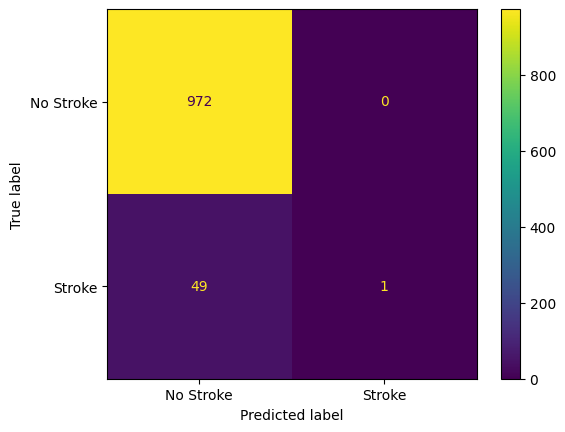

Accuracy: 0.9521
Precision: 1.0000
Recall: 0.0200
F1: 0.0392
ROC AUC: 0.8392
PR AUC: 0.2690


In [ ]:
logisitc = LogisticRegression(random_state = SEED)

def get_metrics(model, X_train, y_train, X_test, y_test, show_cm=False):
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_prob)
    pr_auc = average_precision_score(y_test, y_prob)
    cm = confusion_matrix(y_test, y_pred)

    if show_cm:
        disp = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=['No Stroke', 'Stroke']
        )
        disp.plot()
        plt.show()

    return accuracy, precision, recall, f1, roc_auc, pr_auc

l_accuracy, l_prec, l_recall, l_f1, l_roc_auc, l_pr_auc = get_metrics(logisitc, X_train_scaled, y_train, X_test_scaled, y_test, True)

print(f"Accuracy: {l_accuracy:.4f}")
print(f"Precision: {l_prec:.4f}")
print(f"Recall: {l_recall:.4f}")
print(f"F1: {l_f1:.4f}")
print(f"ROC AUC: {l_roc_auc:.4f}")
print(f"PR AUC: {l_pr_auc:.4f}")

**Question 1.1:** Compare the accuracy of the baseline and of Logistic Regression. What do you conclude?

**Question 1.2:** Look at the confusion matrix and the recall. In the hospital's situation, what does a false negative mean, and which numbers should we trust instead of accuracy?

**Your answer:** Baseline accuracy and Logistic Regression accuracies are same, that means accuracy is misleading on imbalanced data, because even if you chose no stroke on all, you are right 95% of the time

A false negative means a patient had a stroke, but the model predicted no stroke, potentially delaying treatment. We should focus on recall, precision, and F1-score, especially recall, rather than relying on accuracy alone.


---

## Part 2 — Underfitting, Overfitting, Bias and Variance
Use **ROC AUC** (not accuracy) as the score from now on.

### Task 2.1 — Validation curve
For `max_depth` = 1, 2, …, 15 and `None`, record the train ROC AUC and the 5-fold stratified CV ROC AUC (train data only). Plot both curves on one chart (labels, title, legend) and report the best depth by CV AUC.

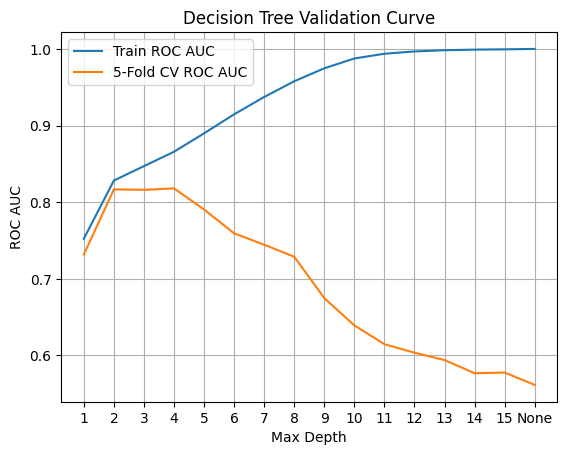

Best depth: 4
Best CV ROC AUC: 0.818


In [ ]:
depths = list(range(1, 16)) + [None]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

train_scores, cv_scores = validation_curve(
    DecisionTreeClassifier(random_state=SEED),
    X_train, y_train,
    param_name='max_depth',
    param_range=depths,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)

train_auc = train_scores.mean(axis=1)
cv_auc = cv_scores.mean(axis=1)

x = np.arange(len(depths))
labels = [str(d) for d in depths]

plt.plot(x, train_auc, label='Train ROC AUC')
plt.plot(x, cv_auc, label='5-Fold CV ROC AUC')
plt.xticks(x, labels)
plt.xlabel('Max Depth')
plt.ylabel('ROC AUC')
plt.title('Decision Tree Validation Curve')
plt.legend()
plt.grid(True)
plt.show()

best_depth = depths[np.argmax(cv_auc)]
print("Best depth:", best_depth)
print("Best CV ROC AUC:", round(cv_auc.max(), 4))

### Task 2.2 — Learning curves
Use `learning_curve` (`scoring='roc_auc'`, train sizes 20%→100%) for a tree with `max_depth=1` and a tree with `max_depth=None`. Plot train and CV AUC against the number of training rows, side by side.

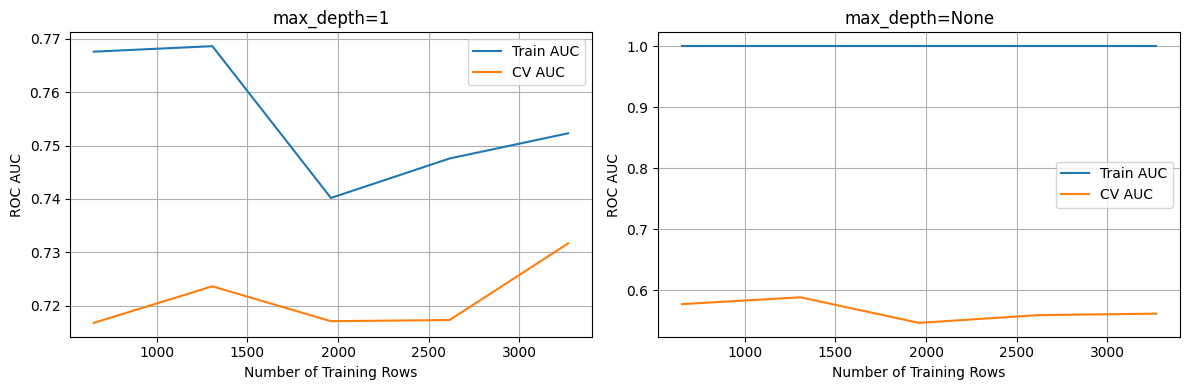

In [ ]:
train_sizes = np.linspace(0.2, 1.0, 5)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for depth, ax in zip([1, None], axes):
    sizes, train_scores, cv_scores = learning_curve(
        DecisionTreeClassifier(max_depth=depth, random_state=SEED),
        X_train, y_train,
        train_sizes=train_sizes,
        cv=cv,
        scoring='roc_auc',
        n_jobs=-1
    )

    ax.plot(sizes, train_scores.mean(axis=1), label='Train AUC')
    ax.plot(sizes, cv_scores.mean(axis=1), label='CV AUC')
    ax.set_title(f'max_depth={depth}')
    ax.set_xlabel('Number of Training Rows')
    ax.set_ylabel('ROC AUC')
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

### Task 2.3 — Measure variance directly
Variance = if the training data changes a little, how much do the predictions change?
1. For `max_depth` = 1, 3 and `None`: draw **40 bootstrap samples** of the train rows (with replacement, same size), fit a tree on each, and collect each tree's predicted stroke probability for every test patient.
2. For every test patient compute the variance of its 40 probabilities, then average over patients. Also report the mean test ROC AUC of the 40 trees and the ROC AUC of the **averaged** prediction.
3. Show the three depths in one table.

*Hints:* `rng.choice(len(X_train), len(X_train), replace=True)` and `X_train.iloc[idx]`; collect an array of shape (40, n_test); `probs.var(axis=0)`.

In [ ]:
rng = np.random.default_rng(SEED)
results = []

for depth in [1, 3, None]:
    probs = []

    for _ in range(40):
        idx = rng.choice(len(X_train), len(X_train), replace=True)
        model = DecisionTreeClassifier(max_depth=depth, random_state=SEED)
        model.fit(X_train.iloc[idx], y_train.iloc[idx])
        probs.append(model.predict_proba(X_test)[:, 1])

    probs = np.array(probs)

    results.append({
        'Max Depth': depth,
        'Mean Variance': probs.var(axis=0).mean(),
        'Mean Test ROC AUC': np.mean([
            roc_auc_score(y_test, p) for p in probs
        ]),
        'Averaged Prediction ROC AUC': roc_auc_score(
            y_test, probs.mean(axis=0)
        )
    })

results_df = pd.DataFrame(results)
print(results_df.round(4).to_string(index=False))

 Max Depth  Mean Variance  Mean Test ROC AUC  Averaged Prediction ROC AUC
       1.0         0.0007             0.7623                       0.8132
       3.0         0.0017             0.7963                       0.8340
       NaN         0.0423             0.5518                       0.7625


**Question 2.1:** From the validation curve: which depths underfit, which overfit, and which depth would you choose? Quote train and CV AUC for one depth in each zone.

**Question 2.2:** From the learning curves: how can you tell high bias from high variance? Will adding more training rows fix either one?

**Question 2.3:** From the variance table: how does variance change with depth? What happens to the AUC of the averaged prediction compared with the single trees? Link this to what Random Forest does (Lab 4).

**Question 2.4:** In your own words: what is the bias-variance trade-off, and where do depth 1, depth 3 and depth None sit?

**Your answer:**
Underfitting: Depth 1. Train AUC ≈ 0.75, CV AUC ≈ 0.73. The tree is too simple.
Best depth: Depth 4, with CV AUC ≈ 0.82. I would choose depth 4 because it gives the best validation performance.
Overfitting: Deep trees, especially None. For None, train AUC ~ 1.00 while CV AUC ~ 0.56, showing poor generalization.

\
High bias: Train and CV AUC are both relatively low and close together, as with depth 1.
High variance: Train AUC is much higher than CV AUC, as with None.
Adding more training rows can help high variance, but may not fix high bias; a more complex model may be needed.

\
Variance increases with depth: 0.0007 -> 0.0017 -> 0.0423. Deeper trees are more sensitive to changes in training data.
Averaging predictions improves AUC compared with the mean AUC of individual trees: depth 1 improves from 0.7623 to 0.8132, depth 3 from 0.7963 to 0.8340, and None from 0.5518 to 0.7625.
Random Forest uses many trees trained on bootstrap samples and averages their predictions, reducing variance and improving generalization.

\
The bias-variance trade-off means balancing a model that is too simple to learn patterns against one that learns the training data too closely.
Depth 1: High bias, low variance — underfits.
Depth 3: Better balance, with stronger validation performance.
Depth None: Low training error but high variance — overfits.

---

## Part 3 — ROC, AUC, Precision-Recall and Thresholds
### Task 3.1 — Compare models with curves
1. Train Logistic Regression (scaled), Decision Tree (`max_depth=3`) and Random Forest (200 trees, `min_samples_leaf=5`, `random_state=SEED`) on the original training data.
2. Draw the ROC curves of the three models on one chart (AUC in the legend, random-guessing diagonal).
3. Draw the Precision-Recall curves on a second chart. Add a horizontal **no-skill line** (the stroke rate) and put the average precision in the legend.

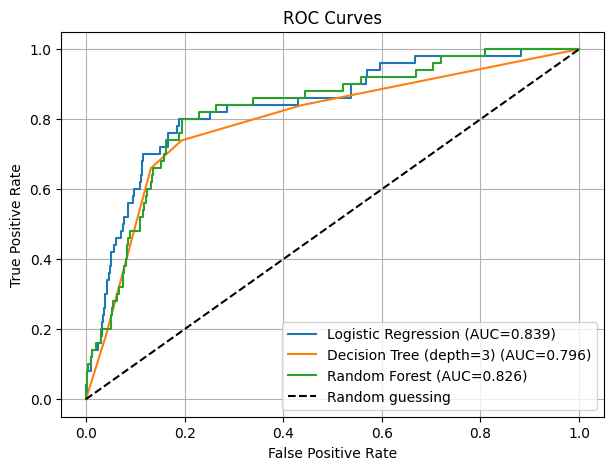

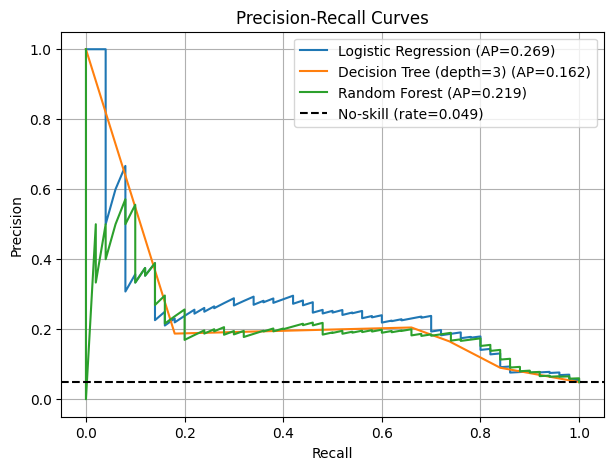

In [ ]:
models = {
    'Logistic Regression': LogisticRegression(random_state=SEED),
    'Decision Tree (depth=3)': DecisionTreeClassifier(max_depth=3, random_state=SEED),
    'Random Forest': RandomForestClassifier(
        n_estimators=200, min_samples_leaf=5, random_state=SEED
    )
}

for name, model in models.items():
    if name == 'Logistic Regression':
        model.fit(X_train_scaled, y_train)
        X_eval = X_test_scaled
    else:
        model.fit(X_train, y_train)
        X_eval = X_test

    models[name] = (model, X_eval)

# ROC curves
plt.figure(figsize=(7, 5))

for name, (model, X_eval) in models.items():
    probs = model.predict_proba(X_eval)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc = roc_auc_score(y_test, probs)
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random guessing')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves')
plt.legend()
plt.grid(True)
plt.show()

# Precision-Recall curves
plt.figure(figsize=(7, 5))
stroke_rate = y_test.mean()

for name, (model, X_eval) in models.items():
    probs = model.predict_proba(X_eval)[:, 1]
    precision, recall, _ = precision_recall_curve(y_test, probs)
    ap = average_precision_score(y_test, probs)
    plt.plot(recall, precision, label=f'{name} (AP={ap:.3f})')

plt.axhline(stroke_rate, color='k', linestyle='--',
            label=f'No-skill (rate={stroke_rate:.3f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curves')
plt.legend()
plt.grid(True)
plt.show()

### Task 3.2 — Choose a decision threshold
The hospital wants to catch **at least 80%** of strokes.
1. Using **only the training data**, get out-of-fold probabilities for Logistic Regression (`cross_val_predict(..., method='predict_proba')`), then find the highest threshold that gives recall ≥ 0.80 on them.
2. Apply that threshold to the **test** probabilities. Report test recall, precision, the confusion matrix, how many patients are flagged and how many are false alarms.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# OOF probabilities using training data only
oof_probs = cross_val_predict(
    LogisticRegression(random_state=SEED),
    X_train_scaled, y_train,
    cv=cv, method='predict_proba'
)[:, 1]

# Highest threshold achieving recall >= 0.80
precision, recall, thresholds = precision_recall_curve(y_train, oof_probs)
valid = np.where(recall[:-1] >= 0.80)[0]
threshold = thresholds[valid[-1]]

print("Threshold:", threshold)

# Fit on all training data, then evaluate on test data
model = LogisticRegression(random_state=SEED)
model.fit(X_train_scaled, y_train)
test_probs = model.predict_proba(X_test_scaled)[:, 1]
y_pred = (test_probs >= threshold).astype(int)

cm = confusion_matrix(y_test, y_pred)
print("Test recall:", recall_score(y_test, y_pred))
print("Test precision:", precision_score(y_test, y_pred, zero_division=0))
print("Confusion matrix:\n", cm)
print("Patients flagged:", y_pred.sum())
print("False alarms:", cm[0, 1])

Threshold: 0.05085915887259651
Test recall: 0.82
Test precision: 0.13442622950819672
Confusion matrix:
 [[708 264]
 [  9  41]]
Patients flagged: 305
False alarms: 264


**Question 3.1:** In Part 1 the recall was very low, yet the ROC AUC of Logistic Regression is far above 0.5. How can both be true? What does AUC measure, and what does the 0.5 threshold have to do with it?

**Question 3.2:** Which curve is more informative for this data — ROC or Precision-Recall — and why? Use the no-skill line in your answer.

**Question 3.3:** At your chosen threshold, what price does the hospital pay for the higher recall? Is it acceptable? Argue both sides in 3–4 lines.

**Your answer:**
Recall was low because the default threshold of 0.5 classified many stroke patients as non-stroke. ROC AUC measures how well the model ranks stroke patients above non-stroke patients across all thresholds. AUC can be high even when recall at the 0.5 threshold is low.

\
Precision-Recall is more informative because only about 5% of patients had strokes. Its no-skill line is the stroke rate (about 0.05), making it easier to judge whether stroke predictions outperform a baseline. ROC curves can look good despite many false positives on imbalanced data.

\
The hospital catches 82% of strokes, but precision is only 13.4%: 264 false alarms among 305 flagged patients. This could be acceptable if follow-up screening is relatively cheap and missing a stroke is dangerous. However, the false alarms consume staff time and resources, so the hospital must decide whether it can handle this workload.

---

## Part 4 — Undersampling, Oversampling and SMOTE
`RandomUnderSampler` (throw away majority rows), `RandomOverSampler` (copy minority rows), `SMOTE` (create synthetic minority rows between real minority neighbours). Another option needs no resampling: `class_weight='balanced'`.

### Task 4.1 — Compare the methods
1. For Logistic Regression (scaled data) and Random Forest (same settings as Part 3) train with: no resampling, `class_weight='balanced'`, random undersampling, random oversampling and SMOTE. **Resample the train set only.**
2. Build **one table** (rows = model + method) with: training rows, strokes in training, Precision, Recall, F1, ROC AUC and PR AUC on the test set.

*Hints:* `from imblearn.over_sampling import SMOTE, RandomOverSampler`; `from imblearn.under_sampling import RandomUnderSampler`; `X_res, y_res = SMOTE(random_state=SEED).fit_resample(X_train, y_train)`. Logistic Regression uses the scaled data, Random Forest the original data.

In [ ]:
methods = {
    'None': None,
    'Balanced weights': 'balanced',
    'Undersampling': RandomUnderSampler(random_state=SEED),
    'Oversampling': RandomOverSampler(random_state=SEED),
    'SMOTE': SMOTE(random_state=SEED)
}

results = []

for model_name in ['Logistic Regression', 'Random Forest']:
    for method_name, sampler in methods.items():

        if model_name == 'Logistic Regression':
            model = LogisticRegression(
                random_state=SEED,
                class_weight='balanced' if method_name == 'Balanced weights' else None
            )
            Xtr, Xte = X_train_scaled, X_test_scaled
        else:
            model = RandomForestClassifier(
                n_estimators=200,
                min_samples_leaf=5,
                random_state=SEED,
                class_weight='balanced' if method_name == 'Balanced weights' else None
            )
            Xtr, Xte = X_train, X_test

        if sampler is not None and method_name != 'Balanced weights':
            X_res, y_res = sampler.fit_resample(Xtr, y_train)
        else:
            X_res, y_res = Xtr, y_train

        model.fit(X_res, y_res)
        probs = model.predict_proba(Xte)[:, 1]
        preds = (probs >= 0.5).astype(int)

        results.append({
            'Model': model_name,
            'Method': method_name,
            'Training Rows': len(X_res),
            'Training Strokes': int(y_res.sum()),
            'Precision': precision_score(y_test, preds, zero_division=0),
            'Recall': recall_score(y_test, preds, zero_division=0),
            'F1': f1_score(y_test, preds, zero_division=0),
            'ROC AUC': roc_auc_score(y_test, probs),
            'PR AUC': average_precision_score(y_test, probs)
        })

results_df = pd.DataFrame(results)
print(results_df.round(3).to_string(index=False))

              Model           Method  Training Rows  Training Strokes  Precision  Recall    F1  ROC AUC  PR AUC
Logistic Regression             None           4087               199      1.000    0.02 0.039    0.839   0.269
Logistic Regression Balanced weights           4087               199      0.134    0.80 0.230    0.839   0.259
Logistic Regression    Undersampling            398               199      0.124    0.82 0.216    0.835   0.233
Logistic Regression     Oversampling           7776              3888      0.133    0.80 0.229    0.838   0.264
Logistic Regression            SMOTE           7776              3888      0.236    0.66 0.347    0.844   0.301
      Random Forest             None           4087               199      0.000    0.00 0.000    0.826   0.219
      Random Forest Balanced weights           4087               199      0.213    0.26 0.234    0.816   0.209
      Random Forest    Undersampling            398               199      0.104    0.84 0.186    0.815 

### Task 4.2 — The classic mistake
1. Apply SMOTE to **all** the data first (train + test together), **then** split 80/20, train a Random Forest and evaluate. This is the wrong order.
2. Put its metrics next to the correct SMOTE-after-split result from Task 4.1 in a two-row table.

In [ ]:
import pandas as pd

# WRONG: Apply SMOTE before splitting
X_smote, y_smote = SMOTE(random_state=SEED).fit_resample(X, y)

X_tr, X_te, y_tr, y_te = train_test_split(
    X_smote, y_smote, test_size=0.2,
    stratify=y_smote, random_state=SEED
)

rf = RandomForestClassifier(
    n_estimators=200, min_samples_leaf=5, random_state=SEED
)
rf.fit(X_tr, y_tr)
probs = rf.predict_proba(X_te)[:, 1]
preds = (probs >= 0.5).astype(int)

wrong = {
    'Method': 'SMOTE before split (wrong)',
    'Precision': precision_score(y_te, preds, zero_division=0),
    'Recall': recall_score(y_te, preds),
    'F1': f1_score(y_te, preds),
    'ROC AUC': roc_auc_score(y_te, probs),
    'PR AUC': average_precision_score(y_te, probs)
}

# Correct SMOTE-after-split result from Task 4.1
correct = results_df[
    (results_df['Model'] == 'Random Forest') &
    (results_df['Method'] == 'SMOTE')
].iloc[0]

comparison = pd.DataFrame([
    wrong,
    {
        'Method': 'SMOTE after split (correct)',
        **{m: correct[m] for m in
           ['Precision', 'Recall', 'F1', 'ROC AUC', 'PR AUC']}
    }
])

print(comparison.round(3).to_string(index=False))

                     Method  Precision  Recall    F1  ROC AUC  PR AUC
 SMOTE before split (wrong)      0.965   0.947 0.956    0.993   0.994
SMOTE after split (correct)      0.129   0.080 0.099    0.789   0.162


**Question 4.1:** For Logistic Regression, what changed after resampling and what did NOT change? Compare Recall, Precision and ROC AUC across the methods and explain why.

**Question 4.2:** Did Random Forest react in the same way? Describe one clear difference and give one possible reason.

**Question 4.3:** Compare the wrong-order result with the correct one. Why are the wrong-order numbers so good, and why can they not be trusted? Explain what leaks from where.

**Question 4.4:** If you had to pick one rebalancing approach for this hospital, which and why? Consider simplicity and cost.

**Your answer:**
Random Forest did not react the same way. Without resampling, it had Recall 0.00, while undersampling raised Recall to 0.84. However, SMOTE performed poorly, with Recall only 0.08 and ROC AUC 0.789. One possible reason is that synthetic examples created by SMOTE do not always represent realistic stroke cases, which can affect how a tree-based model learns.

\
The wrong-order result was dramatically better: ROC AUC 0.993 versus 0.789, and F1 0.956 versus 0.099. This happened because SMOTE was applied before splitting. Synthetic samples were generated using the full dataset, so related original and synthetic examples could end up in both training and test sets. The test set also became artificially balanced instead of reflecting the real, rare-stroke population. This makes evaluation misleading, so the results cannot be trusted to represent real-world performance.

\
I would choose balanced class weights for Logistic Regression as the initial approach. It is simple, computationally inexpensive, and requires no synthetic data generation or extra resampling step. It achieved Recall 0.80 and ROC AUC 0.839. Although Precision was only 0.134, this may be acceptable for an initial screening tool if missing a possible stroke is much more costly than conducting additional assessments. The hospital should evaluate false-positive workload and validate the model clinically before using it with patients.


---

## Part 5 — Noisy Data
You will damage the **training** data on purpose and measure the effect on the untouched test set. Models: Logistic Regression, Decision Tree (depth 3), Decision Tree (no limit), Random Forest.

### Task 5.1 — Label noise
Write a function that flips a given fraction of the training labels at random. For fractions 0, 0.05, 0.10, 0.20 train each model on the noisy labels and record the test ROC AUC. Repeat 5 times with different flips and average (1 repeat for fraction 0). Show a table (rows = fraction, columns = models) and a line plot.

                Logistic Regression  Decision Tree (depth 3)  \
Noise fraction                                                 
0.00                         0.8392                   0.7956   
0.05                         0.8241                   0.8014   
0.10                         0.8052                   0.7830   
0.20                         0.7750                   0.7261   

                Decision Tree (no limit)  Random Forest  
Noise fraction                                           
0.00                              0.5722         0.8264  
0.05                              0.5471         0.7964  
0.10                              0.5184         0.7486  
0.20                              0.5094         0.6692  


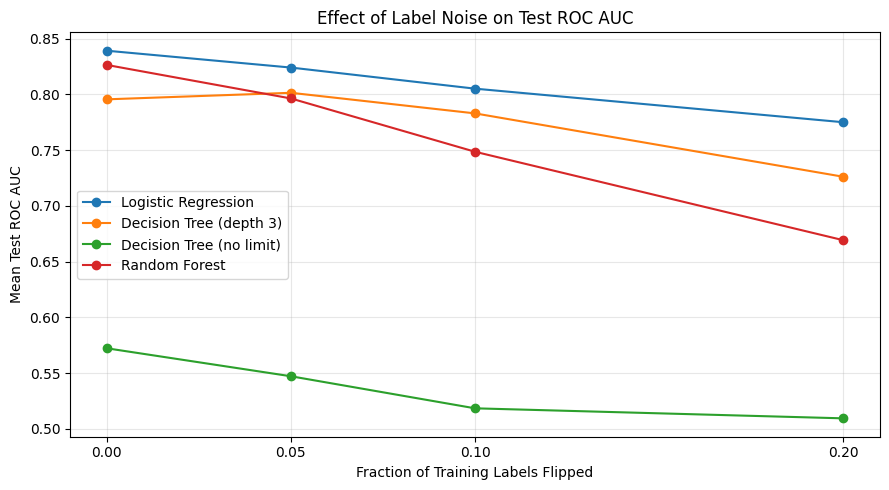

In [ ]:
# Flip a fraction of training labels at random
def flip_labels(y, fraction, seed):
    rng = np.random.default_rng(seed)
    y_noisy = np.asarray(y).copy()
    n_flip = int(len(y_noisy) * fraction)
    indices = rng.choice(len(y_noisy), n_flip, replace=False)
    y_noisy[indices] = 1 - y_noisy[indices]
    return y_noisy

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, random_state=SEED
    ),
    "Decision Tree (depth 3)": DecisionTreeClassifier(
        max_depth=3, random_state=SEED
    ),
    "Decision Tree (no limit)": DecisionTreeClassifier(
        random_state=SEED
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, min_samples_leaf=5, random_state=SEED
    )
}

fractions = [0, 0.05, 0.10, 0.20]
results = []

for fraction in fractions:
    auc_scores = {name: [] for name in models}
    repeats = 1 if fraction == 0 else 5

    for repeat in range(repeats):
        y_noisy = flip_labels(
            y_train, fraction, SEED + repeat
        )

        for name, model in models.items():
            # Use scaled features for Logistic Regression
            if name == "Logistic Regression":
                Xtr, Xte = X_train_scaled, X_test_scaled
            else:
                Xtr, Xte = X_train, X_test

            metrics = get_metrics(
                clone(model), Xtr, y_noisy, Xte, y_test
            )
            auc_scores[name].append(metrics[4])  # ROC AUC

    results.append({
        "Noise fraction": fraction,
        **{
            name: np.mean(scores)
            for name, scores in auc_scores.items()
        }
    })

results_df = pd.DataFrame(results).set_index("Noise fraction")
print(results_df.round(4))

# Line plot
results_df.plot(marker="o", figsize=(9, 5))
plt.xlabel("Fraction of Training Labels Flipped")
plt.ylabel("Mean Test ROC AUC")
plt.title("Effect of Label Noise on Test ROC AUC")
plt.xticks(fractions)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Task 5.2 — Feature noise
Add Gaussian noise to the **train** values of `age`, `avg_glucose_level` and `bmi`: `noise = random normal × (column std) × level`. Levels 0, 0.5, 1, 2; five repeats; test set untouched. Same kind of table and plot. (If you scale for Logistic Regression, fit the scaler on the noisy training data.)

             Logistic Regression  Decision Tree (depth 3)  \
Noise level                                                 
0.0                       0.8391                   0.7956   
0.5                       0.8336                   0.7995   
1.0                       0.8095                   0.7610   
2.0                       0.7691                   0.6942   

             Decision Tree (no limit)  Random Forest  
Noise level                                           
0.0                            0.5722         0.8264  
0.5                            0.5604         0.8109  
1.0                            0.5268         0.7847  
2.0                            0.5320         0.7463  


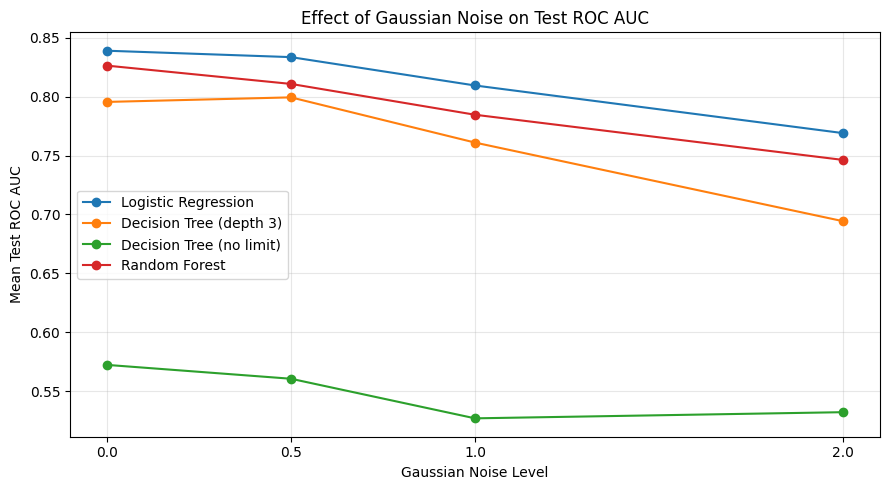

In [ ]:
noise_columns = ['age', 'avg_glucose_level', 'bmi']
levels = [0, 0.5, 1, 2]

# Use the original, unscaled training data
X_train_original = X_train.copy()
X_test_original = X_test.copy()

def add_gaussian_noise(X, columns, level, seed):
    rng = np.random.default_rng(seed)
    X_noisy = X.copy()

    for col in columns:
        std = X[col].std()
        X_noisy[col] = (
            X[col] + rng.normal(0, 1, len(X)) * std * level
        )

    return X_noisy

results = []

for level in levels:
    auc_scores = {name: [] for name in models}

    for repeat in range(5):
        X_noisy = add_gaussian_noise(
            X_train_original, noise_columns, level, SEED + repeat
        )

        for name, model in models.items():
            if name == "Logistic Regression":
                # Fit scaler on noisy training data only
                scaler = StandardScaler()
                Xtr = scaler.fit_transform(X_noisy)
                Xte = scaler.transform(X_test_original)
            else:
                Xtr = X_noisy
                Xte = X_test_original

            fitted_model = clone(model)
            fitted_model.fit(Xtr, y_train)
            probabilities = fitted_model.predict_proba(Xte)[:, 1]

            auc_scores[name].append(
                roc_auc_score(y_test, probabilities)
            )

    results.append({
        "Noise level": level,
        **{
            name: np.mean(scores)
            for name, scores in auc_scores.items()
        }
    })

results_df = pd.DataFrame(results).set_index("Noise level")
print(results_df.round(4))

# Plot
results_df.plot(marker='o', figsize=(9, 5))
plt.xlabel("Gaussian Noise Level")
plt.ylabel("Mean Test ROC AUC")
plt.title("Effect of Gaussian Noise on Test ROC AUC")
plt.xticks(levels)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Task 5.3 — SMOTE and noisy labels
Flip 10% of the training labels (3 different random draws). For Logistic Regression and Random Forest compare **PR AUC and ROC AUC with and without SMOTE** (SMOTE applied after the noise is added).

In [ ]:
results = []

for repeat in range(3):
    # Flip 10% of training labels
    rng = np.random.default_rng(SEED + repeat)
    y_noisy = np.asarray(y_train).copy()

    n_flip = int(len(y_noisy) * 0.10)
    indices = rng.choice(len(y_noisy), n_flip, replace=False)
    y_noisy[indices] = 1 - y_noisy[indices]

    for model_name in ["Logistic Regression", "Random Forest"]:
        model = models[model_name]

        for use_smote in [False, True]:
            Xtr = X_train.copy()
            ytr = y_noisy.copy()

            # SMOTE after label noise, training data only
            if use_smote:
                Xtr, ytr = SMOTE(
                    random_state=SEED + repeat
                ).fit_resample(Xtr, ytr)

            # Scale LR using the current training data
            if model_name == "Logistic Regression":
                scaler = StandardScaler()
                Xtr = scaler.fit_transform(Xtr)
                Xte = scaler.transform(X_test)
            else:
                Xte = X_test

            fitted_model = clone(model)
            fitted_model.fit(Xtr, ytr)
            probs = fitted_model.predict_proba(Xte)[:, 1]

            results.append({
                "Repeat": repeat + 1,
                "Model": model_name,
                "Method": "With SMOTE" if use_smote else "Without SMOTE",
                "ROC AUC": roc_auc_score(y_test, probs),
                "PR AUC": average_precision_score(y_test, probs)
            })

results_df = pd.DataFrame(results)

# Results for each random draw
print(results_df.round(4).to_string(index=False))

# Mean across the 3 random draws
summary = (
    results_df.groupby(["Model", "Method"])[["ROC AUC", "PR AUC"]]
    .mean()
    .reset_index()
)

print("\nMean results across 3 repeats:")
print(summary.round(4).to_string(index=False))

 Repeat               Model        Method  ROC AUC  PR AUC
      1 Logistic Regression Without SMOTE   0.8123  0.2297
      1 Logistic Regression    With SMOTE   0.6757  0.1181
      1       Random Forest Without SMOTE   0.7486  0.1712
      1       Random Forest    With SMOTE   0.6461  0.0720
      2 Logistic Regression Without SMOTE   0.8010  0.2493
      2 Logistic Regression    With SMOTE   0.6393  0.1204
      2       Random Forest Without SMOTE   0.7466  0.1386
      2       Random Forest    With SMOTE   0.6536  0.0776
      3 Logistic Regression Without SMOTE   0.8170  0.1943
      3 Logistic Regression    With SMOTE   0.6563  0.0996
      3       Random Forest Without SMOTE   0.7294  0.1364
      3       Random Forest    With SMOTE   0.6448  0.0720

Mean results across 3 repeats:
              Model        Method  ROC AUC  PR AUC
Logistic Regression    With SMOTE   0.6571  0.1127
Logistic Regression Without SMOTE   0.8101  0.2245
      Random Forest    With SMOTE   0.6482  0.07

**Question 5.1:** Which model is most damaged by noise and which is most stable? Quote numbers at the highest noise level and explain using what you learned in Part 2.

**Question 5.2:** Which hurts more here — label noise or feature noise of a comparable level? Give a short reason.

**Question 5.3:** What did SMOTE do to each model when the labels were noisy? Explain why SMOTE can amplify label noise.

**Your answer:**
The unlimited Decision Tree is most sensitive to feature noise, with ROC AUC dropping from 0.5722 to 0.5320. Logistic Regression is relatively stable, dropping from 0.8391 to 0.7691. This fits Part 2: complex trees can overfit, while simpler linear models are generally less sensitive to noisy features.

\
SMOTE with noisy labels caused a substantial performance drop. However, this comparison doesn't isolate label noise alone, so we cannot conclude label noise is always worse than feature noise.

\
SMOTE worsened both models:
Logistic Regression: ROC AUC 0.8101 -> 0.6571. PR AUC 0.2245 -> 0.1127.
Random Forest: ROC AUC 0.7415 -> 0.6482. PR AUC 0.1487 -> 0.0739.
SMOTE can amplify label noise by generating synthetic minority examples from mislabeled cases, reinforcing incorrect patterns during training.

---

## Part 6 — Final Decision and Conclusion
1. Choose your final approach for the hospital (model + rebalancing method or threshold). Build a final table on the test set comparing the default threshold 0.5 with your choice: Precision, Recall, F1, number of false alarms and number of missed strokes.
2. Write an **Executive Summary** (6–8 lines): what you chose, its recall and precision with numbers, the price paid, how you avoided leakage, and one limitation (think about only 50 stroke patients in the test set, and about how the threshold was chosen).

In [ ]:
# Fit final Logistic Regression with balanced class weights
final_model = LogisticRegression(
    class_weight="balanced", max_iter=1000, random_state=SEED
)
final_model.fit(X_train_scaled, y_train)

# Test probabilities; test set was not used to choose threshold
probs = final_model.predict_proba(X_test_scaled)[:, 1]

thresholds = {
    "Default (0.5)": 0.5,
    "Chosen threshold": threshold
}

rows = []

for name, threshold in thresholds.items():
    preds = (probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, preds, labels=[0, 1]).ravel()

    rows.append({
        "Threshold": name,
        "Precision": precision_score(y_test, preds, zero_division=0),
        "Recall": recall_score(y_test, preds, zero_division=0),
        "F1": f1_score(y_test, preds, zero_division=0),
        "False alarms": fp,
        "Missed strokes": fn
    })

final_table = pd.DataFrame(rows).set_index("Threshold")
print(final_table.round(3))

                  Precision  Recall     F1  False alarms  Missed strokes
Threshold                                                               
Default (0.5)         0.134    0.80  0.230           258              10
Chosen threshold      0.061    0.98  0.115           750               1


**Executive Summary**

For this hospital, I chose Logistic Regression with balanced class weights at the default 0.5 threshold. This model catches 80% of all strokes (Recall = 0.80), missing only 10 out of 50 stroke patients. The trade-off is a low precision of 13.4%, which creates 258 false alarms. However, this is far better than lowering the threshold further, which flagged 750 false alarms to catch only 9 more cases. To prevent data leakage, all scaling, imputing, and threshold choices were learned strictly on the training set. One big limitation is that the test set only contains 50 stroke cases, meaning missing just 2 or 3 extra patients drastically changes the score, so the model needs testing on a much larger patient group.


**Final Reflection:** (a) What was the most surprising result in this lab? (b) If you had one more hour, what would you try next?

**Your answer:**
a: The most surprising result was seeing how bad SMOTE performed when the data had errors. We usually learn that SMOTE fixes imbalanced data, but here it actually amplified label mistakes by creating new fake copies of wrong data, dropping accuracy significantly

\
I would focus on better feature engineering to help the models separate stroke and non-stroke patients more cleanly. For example, combining age, hypertension, and avg_glucose_level into an overall "cardiovascular risk index". I would also test different thresholds specifically for high-risk age groups (like patients over 60) rather than using a single cutoff for everyone

